# Mithun Titus Maria Ruban Raj's Notebook - Mini Project 1

## Goals

- Main Idea: How does the word choice differ between two different authors writing in the same genre and same author writing two different novels in the same genre? (L. Frank Baum & Lewis Carroll)
- Create an issue on a team member's repo
- Respond to the issue that was created on my repo by another team member

## Methods

- Find three novels from Project Gutenberg:
    - Lewis Carroll: Alice's Adventures in Wonderland
    - Lewis Carroll: Sylvie and Bruno
    - L. Frank Baum: The Wonderful Wizard of Oz
- Clean each text (remove stop words) and count word frequencies, normalized to occurrences per 1,000 regular words so books of different lengths can be compared fairly
- Build comparison tables/bar charts for each pair of books
- Identify which words show the biggest gap between books to see if any words are "preferred" by one author/book over another

In [1]:
import requests
import re
from bs4 import BeautifulSoup
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# A standard set of common English stop words
# You can add or remove words later if your professor wants a different approach

STOP_WORDS = {
    "a", "an", "and", "are", "as", "at", "be", "been", "but", "by",
    "for", "from", "had", "has", "have", "he", "her", "hers", "him",
    "his", "i", "if", "in", "into", "is", "it", "its", "me", "my",
    "no", "not", "of", "on", "or", "our", "ours", "she", "so", "that",
    "the", "their", "theirs", "them", "they", "this", "to", "too",
    "was", "we", "were", "what", "when", "where", "which", "who",
    "will", "with", "you", "your", "yours"
}

def clean_and_count(text):
    text = text.lower() # converting to lowercase
    words = re.findall(r"[a-z]+", text) # Keeping alphabetic words only
    words = [word for word in words if word not in STOP_WORDS] # removing stop words
    return Counter(words)

## Functions to download the texts

In [3]:
def fetch_plain_text(url):
    response = requests.get(url)
    response.raise_for_status()
    return response.text

def fetch_html_text(url):
    response = requests.get(url)
    response.raise_for_status()
    soup = BeautifulSoup(response.text, "html.parser")
    for tag in soup(["script", "style"]):
        tag.decompose()
    return soup.get_text(" ")

In [4]:
alice_url = "https://www.gutenberg.org/cache/epub/11/pg11.txt"
sylvie_url = "https://www.gutenberg.org/cache/epub/620/pg620-images.html"
wizard_url = "https://www.gutenberg.org/cache/epub/55/pg55-images.html"

alice_text = fetch_plain_text(alice_url)
print("Alice's Adventures in Wonderland downloaded. Characters:", len(alice_text))

sylvie_text = fetch_html_text(sylvie_url)
print("Sylvie and Bruno downloaded. Characters:", len(sylvie_text))

wizard_text = fetch_html_text(wizard_url)
print("The Wonderful Wizard of Oz downloaded. Characters:", len(wizard_text))

Alice's Adventures in Wonderland downloaded. Characters: 167712
Sylvie and Bruno downloaded. Characters: 440268
The Wonderful Wizard of Oz downloaded. Characters: 235635


## Calculating word frequencies 

In [5]:
TOP_WORD_COUNT = 15 # 15 of the most frequent words get pulled

alice_counts = clean_and_count(alice_text)
sylvie_counts = clean_and_count(sylvie_text)
wizard_counts = clean_and_count(wizard_text)

alice_total = sum(alice_counts.values())
sylvie_total = sum(sylvie_counts.values())
wizard_total = sum(wizard_counts.values())

def normalized_frequency(count, total):
    return (count / total) * 1000

print(f"Alice's Adventures in Wonderland: {len(alice_counts)} unique words, {alice_total} regular words")
print(f"Sylvie and Bruno:                 {len(sylvie_counts)} unique words, {sylvie_total} regular words")
print(f"The Wonderful Wizard of Oz:       {len(wizard_counts)} unique words, {wizard_total} regular words")

Alice's Adventures in Wonderland: 2939 unique words, 17482 regular words
Sylvie and Bruno:                 6338 unique words, 40535 regular words
The Wonderful Wizard of Oz:       3288 unique words, 23440 regular words


## Helper functions for comparing two books

In [6]:
def top_words_table(counts, total, top_n=TOP_WORD_COUNT):
    return pd.DataFrame(
        [
            (word, count, normalized_frequency(count, total))
            for word, count in counts.most_common(top_n)
        ],
        columns=["word", "count", "per_1000_words"]
    )

def compare_books(counts_book1, total_book1, name_book1, counts_book2, total_book2, name_book2, top_n=TOP_WORD_COUNT):
    words = (
        {w for w, c in counts_book1.most_common(top_n)}
        | {w for w, c in counts_book2.most_common(top_n)}
    )
    df = pd.DataFrame({
        "word": sorted(words),
        f"{name_book1}_per_1000": [normalized_frequency(counts_book1[w], total_book1) for w in sorted(words)],
        f"{name_book2}_per_1000": [normalized_frequency(counts_book2[w], total_book2) for w in sorted(words)],
    })
    df["difference"] = df[f"{name_book2}_per_1000"] - df[f"{name_book1}_per_1000"]
    return df.sort_values("difference", ascending=False).reset_index(drop=True)

def plot_comparison(counts_book1, total_book1, name_book1, counts_book2, total_book2, name_book2, title, top_n=TOP_WORD_COUNT):
    words = (
        {w for w, c in counts_book1.most_common(top_n)}
        | {w for w, c in counts_book2.most_common(top_n)}
    )
    chart_df = pd.DataFrame({
        "word": sorted(words),
        name_book1: [normalized_frequency(counts_book1[w], total_book1) for w in sorted(words)],
        name_book2: [normalized_frequency(counts_book2[w], total_book2) for w in sorted(words)],
    }).sort_values(name_book1, ascending=True)

    ax = chart_df.plot(x="word", y=[name_book1, name_book2], kind="barh", figsize=(11, 8))
    ax.set_title(title, fontsize=16)
    ax.set_xlabel("Occurrences per 1,000 regular words")
    ax.set_ylabel("Word")
    ax.legend(title="Book")
    plt.tight_layout()
    plt.show()

## Part 1 - Compare word frequencies between two works of a single author

In [7]:
print("\nTop words in Alice's Adventures in Wonderland:")
display(top_words_table(alice_counts, alice_total))

print("\nTop words in Sylvie and Bruno:")
display(top_words_table(sylvie_counts, sylvie_total))


Top words in Alice's Adventures in Wonderland:


,word,count,per_1000_words
0,said,462,26.427182
1,alice,403,23.052282
2,s,222,12.698776
3,t,218,12.469969
4,all,199,11.383137
5,very,145,8.294246
6,little,129,7.379018
7,out,118,6.749800
8,one,106,6.063379
9,down,103,5.891774



Top words in Sylvie and Bruno:


,word,count,per_1000_words
0,s,640,15.788824
1,said,633,15.616134
2,t,506,12.483039
3,bruno,400,9.868015
4,all,381,9.399285
5,sylvie,344,8.486493
6,one,301,7.425682
7,would,225,5.550759
8,little,223,5.501419
9,lady,217,5.353398


In [8]:
carroll_comparison = compare_books(
    alice_counts, alice_total, "Alice",
    sylvie_counts, sylvie_total, "Sylvie_and_Bruno"
)
display(carroll_comparison)

,word,Alice_per_1000,Sylvie_and_Bruno_per_1000,difference
0,bruno,0.000000,9.868015,9.868015
1,sylvie,0.000000,8.486493,8.486493
2,professor,0.057202,5.304058,5.246857
3,lady,0.171605,5.353398,5.181793
4,s,12.698776,15.788824,3.090049
5,one,6.063379,7.425682,1.362302
6,would,4.747741,5.550759,0.803018
7,t,12.469969,12.483039,0.013070
8,there,5.777371,5.032688,-0.744683
9,do,5.548564,4.711977,-0.836587


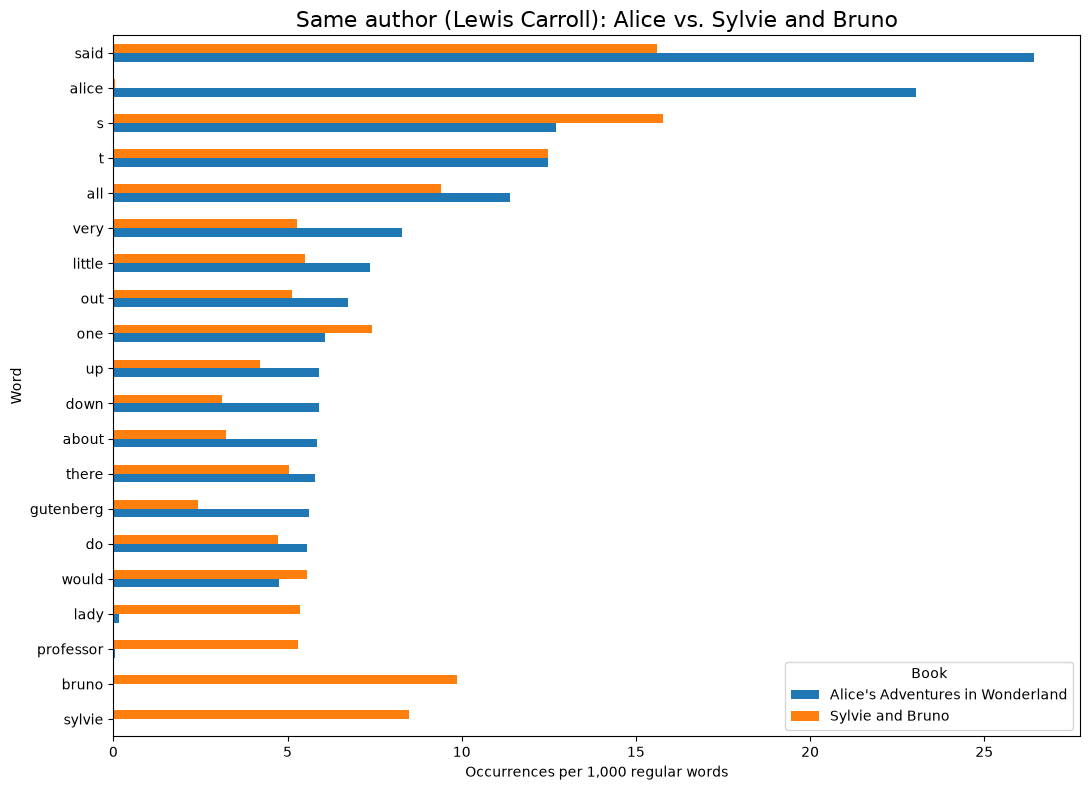

In [9]:
plot_comparison(
    alice_counts, alice_total, "Alice's Adventures in Wonderland",
    sylvie_counts, sylvie_total, "Sylvie and Bruno",
    "Same author (Lewis Carroll): Alice vs. Sylvie and Bruno"
)

## Part 2 - Compare word frequencies between works of two authors

In [10]:
print("Top words in Alice's Adventures in Wonderland:")
display(top_words_table(alice_counts, alice_total))

print("\nTop words in The Wonderful Wizard of Oz:")
display(top_words_table(wizard_counts, wizard_total))

Top words in Alice's Adventures in Wonderland:


,word,count,per_1000_words
0,said,462,26.427182
1,alice,403,23.052282
2,s,222,12.698776
3,t,218,12.469969
4,all,199,11.383137
5,very,145,8.294246
6,little,129,7.379018
7,out,118,6.749800
8,one,106,6.063379
9,down,103,5.891774



Top words in The Wonderful Wizard of Oz:


,word,count,per_1000_words
0,dorothy,369,15.742321
1,said,332,14.163823
2,all,264,11.262799
3,scarecrow,225,9.598976
4,woodman,183,7.807167
5,lion,180,7.679181
6,oz,169,7.209898
7,do,147,6.271331
8,great,142,6.058020
9,tin,140,5.972696


In [11]:
authors_comparison = compare_books(
    alice_counts, alice_total, "Alice",
    wizard_counts, wizard_total, "Wizard_of_Oz"
)
display(authors_comparison)

,word,Alice_per_1000,Wizard_of_Oz_per_1000,difference
0,dorothy,0.000000,15.742321,15.742321
1,scarecrow,0.000000,9.598976,9.598976
2,woodman,0.000000,7.807167,7.807167
3,lion,0.000000,7.679181,7.679181
4,oz,0.000000,7.209898,7.209898
5,tin,0.000000,5.972696,5.972696
6,witch,0.000000,5.503413,5.503413
7,great,2.230866,6.058020,3.827154
8,do,5.548564,6.271331,0.722767
9,then,5.376959,5.418089,0.041130


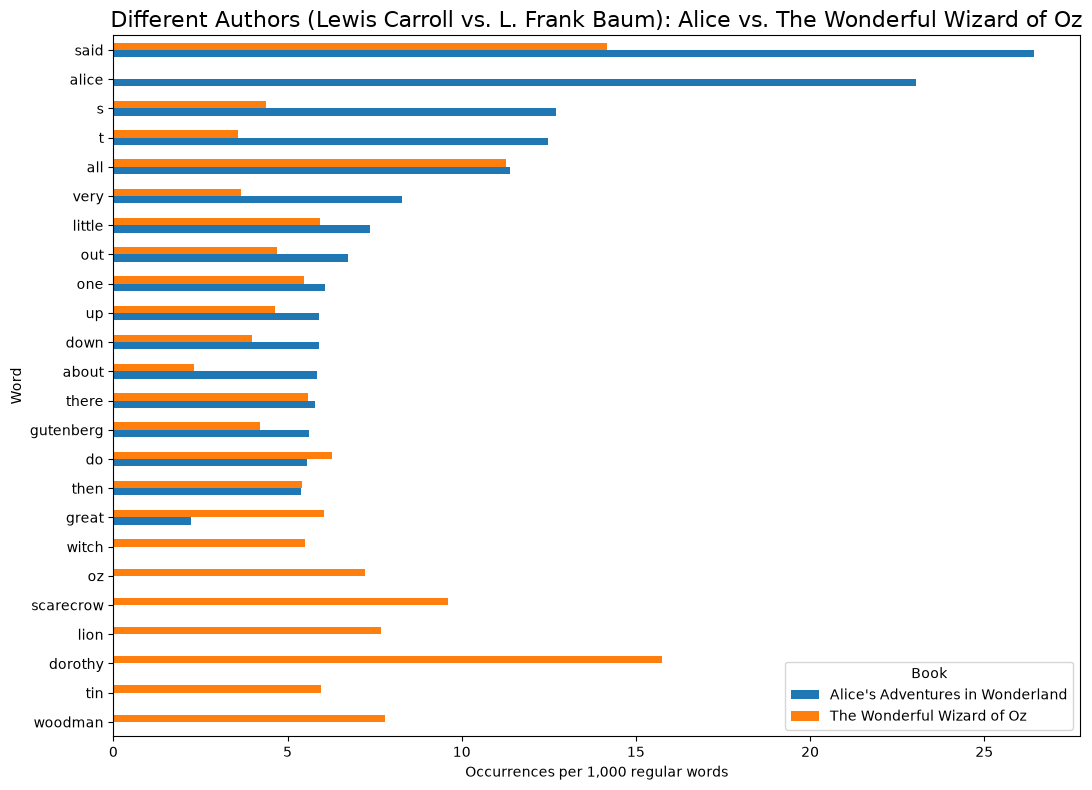

In [12]:
plot_comparison(
    alice_counts, alice_total, "Alice's Adventures in Wonderland",
    wizard_counts, wizard_total, "The Wonderful Wizard of Oz",
    "Different Authors (Lewis Carroll vs. L. Frank Baum): Alice vs. The Wonderful Wizard of Oz"
)

## Part 3 - Are there some words preferred by one author but used less frequently by another author?

In [13]:
def most_distinctive(df, name_book1, name_book2, n=5):
    print(f"Words used much MORE in {name_book2} than in {name_book1}:")
    display(df.head(n)[["word", "difference"]])
    print(f"\nWords used much MORE in {name_book1} than in {name_book2}:")
    display(df.tail(n)[["word", "difference"]].sort_values("difference"))

print("\nSame author: Carroll's Alice vs. Carroll's Sylvie and Bruno")
most_distinctive(carroll_comparison, "Alice", "Sylvie and Bruno")

print("\nDifferent authors: Alice (Carroll) vs. Wizard of Oz (Baum)")
most_distinctive(authors_comparison, "Alice", "Wizard of Oz")


Same author: Carroll's Alice vs. Carroll's Sylvie and Bruno
Words used much MORE in Sylvie and Bruno than in Alice:


,word,difference
0,bruno,9.868015
1,sylvie,8.486493
2,professor,5.246857
3,lady,5.181793
4,s,3.090049



Words used much MORE in Alice than in Sylvie and Bruno:


,word,difference
19,alice,-23.002942
18,said,-10.811048
17,gutenberg,-3.163432
16,very,-3.014857
15,down,-2.783350



Different authors: Alice (Carroll) vs. Wizard of Oz (Baum)
Words used much MORE in Wizard of Oz than in Alice:


,word,difference
0,dorothy,15.742321
1,scarecrow,9.598976
2,woodman,7.807167
3,lion,7.679181
4,oz,7.209898



Words used much MORE in Alice than in Wizard of Oz:


,word,difference
23,alice,-23.052282
22,said,-12.263360
21,t,-8.886351
20,s,-8.304578
19,very,-4.625304


## Extra Credit

In [14]:
TARGET_WORD = "said" # I chose 'said' as the target word

def word_stats(counts, total, word=TARGET_WORD):
    x = counts[word]
    p_hat = x / total
    return x, total, p_hat

books = {
    "Alice's Adventures in Wonderland": (alice_counts, alice_total),
    "Sylvie and Bruno": (sylvie_counts, sylvie_total),
    "The Wonderful Wizard of Oz": (wizard_counts, wizard_total),
}

word_summary = pd.DataFrame([
    {
        "book": name,
        f'count("{TARGET_WORD}")': word_stats(c, t)[0],
        "N_regular_words": t,
        "p_hat": word_stats(c, t)[2],
    }
    for name, (c, t) in books.items()
])
display(word_summary)

,book,"count(""said"")",N_regular_words,p_hat
0,Alice's Adventures in Wonderland,462,17482,0.026427
1,Sylvie and Bruno,633,40535,0.015616
2,The Wonderful Wizard of Oz,332,23440,0.014164


In [15]:
def two_proportion_z_test(x1, n1, x2, n2):
    """Two-proportion z-test for whether p1 == p2 (pooled variance)."""
    p1, p2 = x1 / n1, x2 / n2
    p_pool = (x1 + x2) / (n1 + n2)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    return z, p_value

alice_x, alice_n, alice_p = word_stats(alice_counts, alice_total)
sylvie_x, sylvie_n, sylvie_p = word_stats(sylvie_counts, sylvie_total)
wizard_x, wizard_n, wizard_p = word_stats(wizard_counts, wizard_total)

z_same_author, p_same_author = two_proportion_z_test(alice_x, alice_n, sylvie_x, sylvie_n)
z_diff_author, p_diff_author = two_proportion_z_test(alice_x, alice_n, wizard_x, wizard_n)
z_diff_author2, p_diff_author2 = two_proportion_z_test(sylvie_x, sylvie_n, wizard_x, wizard_n)

print(f"Same author  (Alice vs. Sylvie and Bruno):        z = {z_same_author:.3f}, p-value = {p_same_author:.4f}")
print(f"Diff authors (Alice vs. Wizard of Oz):            z = {z_diff_author:.3f}, p-value = {p_diff_author:.4f}")
print(f"Diff authors (Sylvie and Bruno vs. Wizard of Oz): z = {z_diff_author2:.3f}, p-value = {p_diff_author2:.4f}")
print("\n(A small p-value, e.g. < 0.05, means the two books' rates of \"" + TARGET_WORD + "\" differ by more than chance would predict.)")

Same author  (Alice vs. Sylvie and Bruno):        z = 8.780, p-value = 0.0000
Diff authors (Alice vs. Wizard of Oz):            z = 8.897, p-value = 0.0000
Diff authors (Sylvie and Bruno vs. Wizard of Oz): z = 1.452, p-value = 0.1465

(A small p-value, e.g. < 0.05, means the two books' rates of "said" differ by more than chance would predict.)


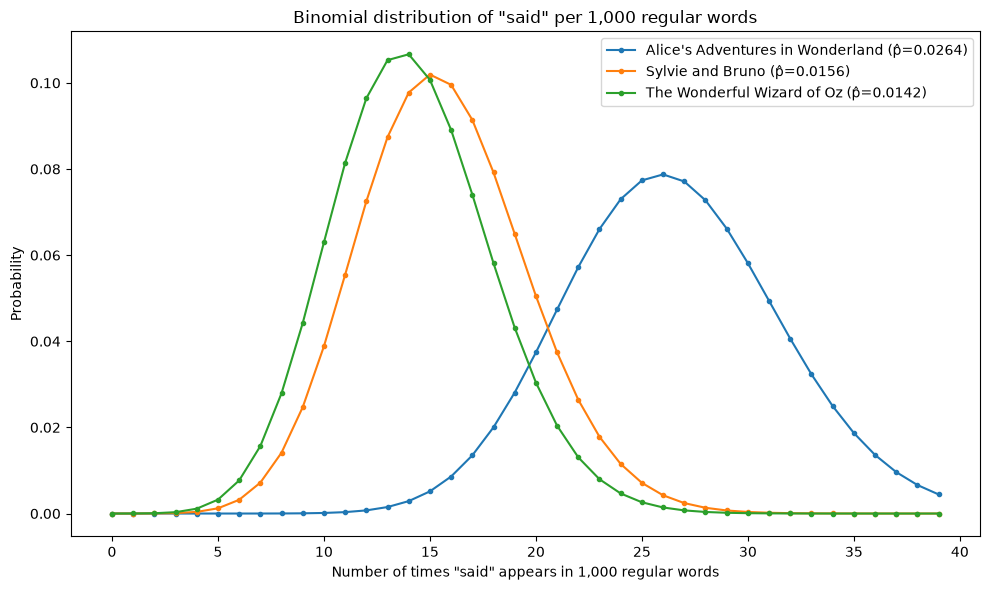

In [16]:
n_sample = 1000
k = np.arange(0, 40)

plt.figure(figsize=(10, 6))
for name, (c, t) in books.items():
    _, _, p_hat = word_stats(c, t)
    pmf = stats.binom.pmf(k, n_sample, p_hat)
    plt.plot(k, pmf, marker="o", markersize=3, label=f"{name} (p\u0302={p_hat:.4f})")

plt.title(f'Binomial distribution of "{TARGET_WORD}" per 1,000 regular words')
plt.xlabel(f'Number of times "{TARGET_WORD}" appears in 1,000 regular words')
plt.ylabel("Probability")
plt.legend()
plt.tight_layout()
plt.show()

## Final Findings

1. Comparing word frequencies between two works/books of a single author
   Comparing Lewis Carroll's *Alice's Adventures in Wonderland* and *Sylvie and Bruno*, I noticed that ordinary words diverge noticeably even after setting aside character names. The word "said" appears at 26.4 per 1000 words in Alice vs. only 15.6 in Sylvie and Bruno. The word "very" is used almost 1.6x more often in Alice (8.29 vs. 5.28). So word frequencies are not nearly identical even within the same author's body of work.

2. Compare word frequencies between works of two authors
   Comparing Alice to Baum's *The Wonderful Wizard of Oz*, beyond the character-name differences, Carroll's Alice uses "very" and "about" much more heavily (8.29 vs. 3.67 and 5.83 vs. 2.30 per 1,000 words), while both books use function words like "all," "there," and "one" at fairly similar rates, thus showing some but not dramatic stylistic separation between the two authors.

3. Are there words preferred by one author but used less frequently by another?
   Yes. The words "very," "about," and "said" are all noticeably more common in Alice than in either of the other two books (e.g., "said" at 26.4/1,000 in Alice vs. 15.6 and 14.2/1,000 in the other two), but this makes Alice stand out from both books rather than cleanly splitting along authorship lines.

Extra Credit:-

The binomial rate of "said" differs significantly between *Alice* and *Sylvie and Bruno* (same author: z = 8.78, p ≈ 0.0000) and between *Alice* and *Wizard of Oz* (different authors: z = 8.90, p ≈ 0.0000) but not between *Sylvie and Bruno* and *Wizard of Oz* (different authors: z = 1.45, p = 0.1465). This shows "said"-frequency doesn't cleanly track authorship: the two Carroll books are actually the most different pair for this word, suggesting the rate is driven more by each book's narrative style (how dialogue-heavy it is) than by a stable per-author fingerprint.